# 07 · 三阶与其他数值变换：Ridge / RandomForest

比较 **6 种表示 × 2 种模型**，沿用已保存的 seed=42 外层五折，以平均验证 **ROC AUC** 为主指标。

|表示|数值部分维度|变换|
|---|---:|---|
|基础表示 `base`|13|截尾、填补、标准化后的原值 $z$|
|二阶 `poly2`|104|原值、平方、两两乘积|
|三阶 `poly3`|559|保留一阶和二阶，再增加立方、平方×其他变量、三个变量相乘|
|分位数正态 `quantile`|13|按训练折的经验分位数映射到正态分布|
|RBF 近似 `rbf`|269|13 原值 + 256 个随机傅里叶特征|
|样条 `spline`|91|13 原值 + 78 个三次 B 样条特征|

每组都额外保留 **43 个类别字段的 One-Hot 和 13 个缺失标记**；变换仅作用在 13 个连续数值字段，不加入类别交叉或数值×类别交叉。三阶维度不包含常数项。

RBF 借用核映射思路，使用 $K(z,z')=\exp(-\lVert z-z'\rVert^2/13)$ 的有限随机近似，追加原值后再逐列标准化。它不是精确核 Ridge；这轮只验证一个预先固定的 gamma、维度和随机种子。样条表示给每个数值变量加入平滑曲线，帮助线性模型表示单变量非线性。

先运行 `01_hmda_data_preparation.ipynb`。支持从项目目录、父目录或 Colab Drive 项目目录运行，无需 GPU。上一轮的二阶结果仍在 `artifacts/polynomial_models/`，本轮独立写入 `artifacts/transformation_models/`。

## 1. 配置与比较规则

默认完整五折，105,000 行。`smoke` 仅检查通路。相同数据、代码和配置的完成结果会自动复用；修改代码后先保存 notebook，再运行。将 `REUSE_COMPLETED_RUN=False` 可重训。

所有表示共享训练折 P0.1 / P99.9 截尾、中位数和类别词表。各变换独立只在训练折拟合，再按训练折标准化数值特征。验证标签只用于计算 AUC。Ridge 的 alpha=1、LSQR tol=1e-5；增加到 5000 次迭代上限仅用于三阶收敛，不按外层 AUC 选择参数。

RF 使用 200 棵树、深度 16、叶节点至少 10 个样本。每个节点的候选特征数量固定为该折基础输入维度的平方根，六种表示使用相同整数和种子。逐表示创建矩阵并释放，避免同时保存六套高维数据。

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import sparse
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, PolynomialFeatures, StandardScaler,
                                   QuantileTransformer, SplineTransformer)
from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from threadpoolctl import threadpool_limits

RUN_MODE = os.environ.get('HMDA_TRANSFORM_MODE', 'full').lower()
REUSE_COMPLETED_RUN = True
N_JOBS = int(os.environ.get('HMDA_TRANSFORM_THREADS', '4'))
SEED = 42
RIDGE_ALPHA = 1.0
RIDGE_MAX_ITER = 5000
RBF_COMPONENTS = 256
RBF_GAMMA = 1 / 13
QUANTILE_N_QUANTILES = 1000
SPLINE_N_KNOTS = 5
CLIP_QUANTILES = (0.001, 0.999)
RF_TREES = int(os.environ.get('HMDA_TRANSFORM_TREES', '200'))
RF_MAX_DEPTH = 16
RF_MIN_SAMPLES_LEAF = 10
SMOKE_ROWS = 3000
SMOKE_TREES = 12
NOTEBOOK_NAME = '07_hmda_transformations_comparison.ipynb'
PROJECT_NAME = 'demandes-de-pret-immobilier-aux-etats-unis'

def require(condition, message):
    if not bool(condition):
        raise ValueError(message)

require(RUN_MODE in {'full', 'smoke'}, '模式只能为 full / smoke')
require(N_JOBS >= 1 and RF_TREES >= 1 and RIDGE_ALPHA > 0, '线程、树数和 alpha 必须为正数')
if CLIP_QUANTILES is not None:
    require(0 <= CLIP_QUANTILES[0] < CLIP_QUANTILES[1] <= 1, '截尾分位数范围错误')

explicit_project = os.environ.get('HMDA_PROJECT_DIR')
candidates = ([Path(explicit_project).expanduser()] if explicit_project else [
    Path.cwd(), Path.cwd() / PROJECT_NAME,
    Path('/content/drive/MyDrive/Colab Notebooks') / PROJECT_NAME,
])
PROJECT_DIR = next((p.resolve() for p in candidates
                    if (p / 'artifacts/prepared/manifest.json').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('未找到 prepared 数据；先运行 01，或设置 HMDA_PROJECT_DIR 为项目文件夹')
PREPARED_DIR = PROJECT_DIR / 'artifacts/prepared'
OUTPUT_ROOT = PROJECT_DIR / 'artifacts/transformation_models'
print(f'模式: {RUN_MODE} | Python: {sys.executable} | 项目: {PROJECT_DIR}')
if RUN_MODE == 'smoke':
    display(Markdown('**SMOKE：仅验证代码通路，不是正式性能结果。**'))

模式: full | Python: /opt/anaconda3/bin/python | 项目: /Users/zyouwei/Documents/M2/app_supervise/projet/demandes-de-pret-immobilier-aux-etats-unis


## 2. 读取并验证固定数据与五折

检查准备文件和原始 CSV 的 SHA256、列顺序、标签和 ID 对齐，并逐行复核 seed=42 的固定折分配。`id` 与 `accepted` 不作为输入；无标签测试集不参与本次 AUC 验证。

In [2]:
def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

manifest_path = PREPARED_DIR / 'manifest.json'
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
for folder, entries in [(PREPARED_DIR, manifest['output_files']),
                        (PROJECT_DIR, manifest['source_files'])]:
    for name, info in entries.items():
        require(sha256_file(folder / name) == info['sha256'], f'文件已变化：{name}')
schema = json.loads((PREPARED_DIR / 'schema.json').read_text(encoding='utf-8'))
require(schema['schema_version'] == manifest['schema_version'] == '1.0', 'schema 版本错误')
NUMERIC_COLUMNS = schema['numeric_columns']
CATEGORICAL_COLUMNS = schema['categorical_columns']
FEATURE_COLUMNS = schema['feature_columns']
require(len(NUMERIC_COLUMNS) == 13 and len(CATEGORICAL_COLUMNS) == 43,
        '预期 13 数值字段、43 类别字段')
require(len(set(FEATURE_COLUMNS)) == 56
        and set(NUMERIC_COLUMNS).isdisjoint(CATEGORICAL_COLUMNS)
        and set(NUMERIC_COLUMNS + CATEGORICAL_COLUMNS) == set(FEATURE_COLUMNS), '字段分组错误')
require(not {'id', 'accepted'} & set(FEATURE_COLUMNS), '标签或 ID 混入特征')

X = pd.read_csv(PREPARED_DIR / 'train_features.csv', dtype=str, keep_default_na=False)
require(X.columns.tolist() == FEATURE_COLUMNS, '输入列顺序错误')
for col in NUMERIC_COLUMNS:
    X[col] = pd.to_numeric(X[col].replace('', np.nan), errors='raise').astype('float64')
require(not np.isinf(X[NUMERIC_COLUMNS].to_numpy()).any(), '数值包含无穷大')
require(not X[CATEGORICAL_COLUMNS].eq('').any().any(), '类别缺失应已规范为 MISSING')
labels = pd.read_csv(PREPARED_DIR / 'train_labels.csv', dtype=str, keep_default_na=False)
fold_frame = pd.read_csv(PREPARED_DIR / 'folds.csv', dtype=str, keep_default_na=False)
require(labels.columns.tolist() == ['id', 'accepted'] and fold_frame.columns.tolist() == ['id', 'fold'],
        '标签或折文件列错误')
require(len(X) == len(labels) == len(fold_frame) == manifest['n_rows']['train'], '行数错误')
require(labels['id'].is_unique and labels['id'].ne('').all(), 'ID 无效')
require(labels['id'].equals(fold_frame['id']), '标签与折 ID 错位')
require(set(labels['accepted']) == {'0', '1'}, '目标必须是 0 / 1')
y = labels['accepted'].astype('int8').to_numpy()
train_ids = labels['id'].to_numpy()
fold_assignment = pd.to_numeric(fold_frame['fold'], errors='raise').to_numpy()
require(set(fold_assignment) == {1, 2, 3, 4, 5}, '固定折错误')
require(manifest['seed'] == 42 and manifest['n_splits'] == 5, '固定折协议错误')
expected_folds = np.zeros(len(y), dtype=np.int8)
for fold, (_, valid_idx) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(X, y), 1):
    expected_folds[valid_idx] = fold
require(np.array_equal(fold_assignment, expected_folds), '折分配未复现 seed42 五折')
raw_identity = pd.read_csv(PROJECT_DIR / 'train.csv', usecols=['id', 'accepted'], dtype=str)
require(labels.equals(raw_identity[['id', 'accepted']]), '准备标签与原始文件错位')

if RUN_MODE == 'smoke':
    selected, _ = train_test_split(np.arange(len(y)), train_size=min(SMOKE_ROWS, len(y) - 10),
                                  stratify=fold_assignment * 2 + y, random_state=SEED)
    selected = np.sort(selected)
else:
    selected = np.arange(len(y))
X_run = X.iloc[selected].reset_index(drop=True)
y_run, ids_run, folds_run = y[selected], train_ids[selected], fold_assignment[selected]
FOLDS_TO_RUN = [1, 2] if RUN_MODE == 'smoke' else [1, 2, 3, 4, 5]
del X, raw_identity
print(f'验证通过：{len(y_run):,} 行，56 原字段；评估折 {FOLDS_TO_RUN}')
display(pd.crosstab(folds_run, y_run, rownames=['fold'], colnames=['accepted']))

验证通过：105,000 行，56 原字段；评估折 [1, 2, 3, 4, 5]


accepted,0,1
fold,,
1,3151,17849
2,3151,17849
3,3151,17849
4,3151,17849
5,3152,17848


## 3. 折内数值映射

基础与二阶保持上一轮的实现、数据和参数口径。三阶多项式包含全部一、二、三阶项；RBF 和样条保留原数值再追加非线性项；分位数变换则替换数值坐标。它们检验不同类型的非线性表示。

类别 One-Hot 和缺失标记每折仅拟合一次，两模型使用相同表示矩阵。所有数值变换均独立于验证标签。样条使用固定数量的均匀结点与常数外推；分位数变换不抽样训练折，最多 1000 个分位数。

In [3]:
representation_names = {
    'base': '基础表示', 'poly2': '二阶组合', 'poly3': '三阶组合',
    'quantile': '分位数正态', 'rbf': '原值 + RBF 近似', 'spline': '原值 + 样条',
}
MODEL_NAMES = ['Ridge', 'RandomForest']
VARIANTS = [f'{model}_{rep}' for model in MODEL_NAMES for rep in representation_names]

def fold_representation_iterator(train_frame, valid_frame):
    prep_started = time.perf_counter()
    fit_num = train_frame[NUMERIC_COLUMNS].to_numpy(dtype=float)
    val_num = valid_frame[NUMERIC_COLUMNS].to_numpy(dtype=float)
    fit_missing = sparse.csr_matrix(np.isnan(fit_num).astype(np.float32))
    val_missing = sparse.csr_matrix(np.isnan(val_num).astype(np.float32))
    require(np.isfinite(fit_num).any(axis=0).all(), '训练折某数值字段全缺失')
    if CLIP_QUANTILES is not None:
        lower, upper = np.nanquantile(fit_num, CLIP_QUANTILES, axis=0)
        fit_num = np.clip(fit_num, lower, upper)
        val_num = np.clip(val_num, lower, upper)
    imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    fit_num = imputer.fit_transform(fit_num)
    val_num = imputer.transform(val_num)
    scaler = StandardScaler()
    fit_z = scaler.fit_transform(fit_num)
    val_z = scaler.transform(val_num)
    require(fit_z.shape[1] == val_z.shape[1] == 13, '基础数值维度错误')
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=True, dtype=np.float32)
    fit_cat = encoder.fit_transform(train_frame[CATEGORICAL_COLUMNS])
    val_cat = encoder.transform(valid_frame[CATEGORICAL_COLUMNS])
    base_width = 13 + 13 + fit_cat.shape[1]
    rf_max_features = max(1, math.isqrt(base_width))
    shared_prep_seconds = time.perf_counter() - prep_started

    for rep in representation_names:
        started = time.perf_counter()
        if rep == 'base':
            fit_values, val_values = fit_z, val_z
        elif rep in {'poly2', 'poly3'}:
            degree = 2 if rep == 'poly2' else 3
            mapping = PolynomialFeatures(degree=degree, include_bias=False)
            # 与上一轮二阶完全相同；三阶先转 float32 控制峰值内存。
            fit_values = mapping.fit_transform(fit_z)
            val_values = mapping.transform(val_z)
            if rep == 'poly3':
                fit_values = fit_values.astype(np.float32)
                val_values = val_values.astype(np.float32)
            require(fit_values.shape[1] == (104 if rep == 'poly2' else 559), '多项式维度错误')
        elif rep == 'quantile':
            mapping = QuantileTransformer(n_quantiles=min(QUANTILE_N_QUANTILES, len(fit_num)),
                                          output_distribution='normal', subsample=None,
                                          random_state=SEED)
            fit_values = mapping.fit_transform(fit_num)
            val_values = mapping.transform(val_num)
        elif rep == 'rbf':
            mapping = RBFSampler(gamma=RBF_GAMMA, n_components=RBF_COMPONENTS, random_state=SEED)
            with threadpool_limits(limits=N_JOBS):
                fit_values = np.hstack([fit_z, mapping.fit_transform(fit_z)])
                val_values = np.hstack([val_z, mapping.transform(val_z)])
        elif rep == 'spline':
            mapping = SplineTransformer(n_knots=SPLINE_N_KNOTS, degree=3, knots='uniform',
                                        include_bias=False, extrapolation='constant')
            fit_values = np.hstack([fit_z, mapping.fit_transform(fit_z)])
            val_values = np.hstack([val_z, mapping.transform(val_z)])
        else:
            raise ValueError(rep)
        if rep != 'base':
            mapped_scaler = StandardScaler()
            fit_values = mapped_scaler.fit_transform(fit_values)
            val_values = mapped_scaler.transform(val_values)
        numeric_features = fit_values.shape[1]
        expected_numeric = {'base': 13, 'poly2': 104, 'poly3': 559,
                            'quantile': 13, 'rbf': 13 + RBF_COMPONENTS,
                            'spline': 13 * (1 + SPLINE_N_KNOTS + 3 - 2)}
        require(numeric_features == expected_numeric[rep], f'{rep} 数值维度错误')
        fit_matrix = sparse.hstack([sparse.csr_matrix(fit_values, dtype=np.float32),
                                   fit_missing, fit_cat], format='csr', dtype=np.float32)
        val_matrix = sparse.hstack([sparse.csr_matrix(val_values, dtype=np.float32),
                                   val_missing, val_cat], format='csr', dtype=np.float32)
        require(fit_matrix.shape[1] == val_matrix.shape[1], '矩阵维度错位')
        require(np.isfinite(fit_matrix.data).all() and np.isfinite(val_matrix.data).all(),
                '映射产生了非有限值')
        info = {'base_width': base_width, 'numeric_features': numeric_features,
                'features': fit_matrix.shape[1], 'rf_max_features': rf_max_features,
                'preprocess_seconds': shared_prep_seconds + time.perf_counter() - started}
        yield rep, fit_matrix, val_matrix, info
        del fit_matrix, val_matrix, fit_values, val_values
        gc.collect()

display(pd.DataFrame([
    {'representation': rep, 'description': name, 'numeric_features': dim}
    for (rep, name), dim in zip(representation_names.items(), [13, 104, 559, 13, 269, 91])
]))

,representation,description,numeric_features
0,base,基础表示,13
1,poly2,二阶组合,104
2,poly3,三阶组合,559
3,quantile,分位数正态,13
4,rbf,原值 + RBF 近似,269
5,spline,原值 + 样条,91


## 4. 完整五折训练

Ridge 用连续决策分数计算 AUC，RF 用批准类概率。每折依次生成六种表示，各训练两种模型。Ridge 达到迭代上限会中止并标记失败，避免把未收敛模型当作正式结果。

逐折保存预测、指标和完成状态；输出校验及图表都通过才标记 `complete`。仅完整且配置相同的完成结果可复用。`smoke` 仍保留旧折分配，只取少量样本、前两个验证折和 12 棵树。

In [4]:
nb_path = PROJECT_DIR / NOTEBOOK_NAME
require(nb_path.is_file(), '请先将 notebook 保存到项目目录')
nb_source = json.loads(nb_path.read_text(encoding='utf-8'))
code_text = '\n'.join(''.join(c['source']) for c in nb_source['cells'] if c['cell_type'] == 'code')
versions = {name: importlib.metadata.version(name)
            for name in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib']}
config = {
    'mode': RUN_MODE, 'formal_result': RUN_MODE == 'full', 'n_rows': len(y_run),
    'folds_to_run': FOLDS_TO_RUN, 'seed': SEED, 'n_jobs': N_JOBS,
    'numeric_columns': NUMERIC_COLUMNS, 'categorical_columns': CATEGORICAL_COLUMNS,
    'representations': list(representation_names),
    'clip_quantiles': CLIP_QUANTILES, 'numeric_preprocessing': 'train-only clip/median/scaling',
    'missing_flags': 13, 'polynomial_degrees': [2, 3], 'include_bias': False,
    'rbf': {'gamma': RBF_GAMMA, 'n_components': RBF_COMPONENTS, 'append_original': True},
    'quantile': {'n_quantiles': QUANTILE_N_QUANTILES, 'output_distribution': 'normal', 'subsample': None},
    'spline': {'n_knots': SPLINE_N_KNOTS, 'degree': 3, 'knots': 'uniform',
               'include_bias': False, 'extrapolation': 'constant', 'append_original': True},
    'ridge': {'alpha': RIDGE_ALPHA, 'solver': 'lsqr', 'tol': 1e-5, 'max_iter': RIDGE_MAX_ITER},
    'random_forest': {'n_estimators': SMOKE_TREES if RUN_MODE == 'smoke' else RF_TREES,
                      'max_depth': RF_MAX_DEPTH, 'min_samples_leaf': RF_MIN_SAMPLES_LEAF,
                      'max_features': 'same integer: floor(sqrt(base_width)) in each fold'},
    'data_hashes': {'manifest.json': sha256_file(manifest_path),
                   **{k: v['sha256'] for k, v in manifest['output_files'].items()}},
    'code_sha256': hashlib.sha256(code_text.encode()).hexdigest(),
    'python': platform.python_version(), 'versions': versions,
    'auc_primary': 'mean validation-fold ROC AUC; accepted=1',
}
signature = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
RUN_DIR = None
if REUSE_COMPLETED_RUN:
    for existing in sorted(OUTPUT_ROOT.glob('*'), reverse=True):
        status_path = existing / 'status.json'
        if not status_path.is_file():
            continue
        try:
            cached_status = json.loads(status_path.read_text())
        except (OSError, json.JSONDecodeError):
            continue
        required_files = ['config.json', 'fold_metrics.csv', 'oof_predictions.csv',
                          'auc_summary.csv', 'paired_auc_deltas.csv', 'delta_summary.csv',
                          'poly3_vs_poly2.csv', 'auc_comparison.png', 'mean_roc.png']
        if (cached_status.get('state') == 'complete' and cached_status.get('signature') == signature
                and all((existing / name).is_file() for name in required_files)):
            RUN_DIR = existing
            break

if RUN_DIR is not None:
    fold_metrics = pd.read_csv(RUN_DIR / 'fold_metrics.csv')
    oof = pd.read_csv(RUN_DIR / 'oof_predictions.csv', dtype={'id': str})
    print(f'复用已完成的相同实验：{RUN_DIR.name}')
else:
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    RUN_DIR = OUTPUT_ROOT / f'{stamp}_{RUN_MODE}'
    RUN_DIR.mkdir(exist_ok=False)
    (RUN_DIR / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2))
    status = {'state': 'running', 'signature': signature, 'mode': RUN_MODE,
              'formal_result': RUN_MODE == 'full', 'completed_folds': []}
    def save_status():
        (RUN_DIR / 'status.json').write_text(json.dumps(status, ensure_ascii=False, indent=2))
    save_status()
    oof = pd.DataFrame({'id': ids_run, 'accepted': y_run, 'fold': folds_run})
    for variant in VARIANTS:
        oof[variant] = np.nan
    fold_rows = []
    try:
        for fold in FOLDS_TO_RUN:
            train_idx = np.flatnonzero(folds_run != fold)
            valid_idx = np.flatnonzero(folds_run == fold)
            require(not np.intersect1d(train_idx, valid_idx).size, '训练验证重叠')
            require(set(y_run[train_idx]) == set(y_run[valid_idx]) == {0, 1}, '折缺少类别')
            print(f'Fold {fold}: {len(train_idx):,} train / {len(valid_idx):,} valid', flush=True)
            for rep, fit_matrix, val_matrix, info in fold_representation_iterator(
                    X_run.iloc[train_idx], X_run.iloc[valid_idx]):
                print(f' {rep}: numeric={info["numeric_features"]}, total={info["features"]}, '
                      f'RF candidates={info["rf_max_features"]}', flush=True)
                for model_name in MODEL_NAMES:
                    variant = f'{model_name}_{rep}'
                    require(oof.loc[valid_idx, variant].isna().all(), 'OOF 行被重复写入')
                    if model_name == 'Ridge':
                        model = RidgeClassifier(**config['ridge'])
                    else:
                        model = RandomForestClassifier(
                            n_estimators=config['random_forest']['n_estimators'],
                            max_depth=RF_MAX_DEPTH, min_samples_leaf=RF_MIN_SAMPLES_LEAF,
                            max_features=info['rf_max_features'], random_state=SEED,
                            n_jobs=N_JOBS, class_weight=None)
                    started = time.perf_counter()
                    with threadpool_limits(limits=N_JOBS):
                        model.fit(fit_matrix, y_run[train_idx])
                        if model_name == 'Ridge':
                            require(model.classes_.tolist() == [0, 1], 'Ridge 正类方向错误')
                            ridge_iterations = int(np.max(model.n_iter_))
                            require(ridge_iterations < RIDGE_MAX_ITER,
                                    f'{variant} 到达迭代上限，需要提高迭代预算后重新运行')
                            score = model.decision_function(val_matrix)
                        else:
                            ridge_iterations = np.nan
                            pos_idx = np.flatnonzero(model.classes_ == 1).item()
                            score = model.predict_proba(val_matrix)[:, pos_idx]
                    elapsed = time.perf_counter() - started
                    require(score.shape == (len(valid_idx),) and np.isfinite(score).all(), '预测无效')
                    auc = float(roc_auc_score(y_run[valid_idx], score))
                    oof.loc[valid_idx, variant] = score
                    fold_rows.append({'model': model_name, 'representation': rep, 'variant': variant,
                                      'fold': fold, 'auc': auc, 'train_rows': len(train_idx),
                                      'valid_rows': len(valid_idx), 'features': info['features'],
                                      'numeric_features': info['numeric_features'],
                                      'rf_max_features': info['rf_max_features'] if model_name == 'RandomForest' else np.nan,
                                      'preprocess_seconds': info['preprocess_seconds'],
                                      'fit_predict_seconds': elapsed, 'ridge_iterations': ridge_iterations})
                    print(f'  {variant:<24} AUC={auc:.6f}  {elapsed:.1f}s '
                          + (f'iter={ridge_iterations}' if model_name == 'Ridge' else ''), flush=True)
                    pd.DataFrame(fold_rows).to_csv(RUN_DIR / 'fold_metrics.csv', index=False)
                    del model
                del fit_matrix, val_matrix
            oof.to_csv(RUN_DIR / 'oof_predictions.csv', index=False)
            status['completed_folds'].append(fold)
            save_status()
            gc.collect()
        fold_metrics = pd.DataFrame(fold_rows)
        status['state'] = 'trained'
        save_status()
    except BaseException as exc:
        status.update(state='failed', error=f'{type(exc).__name__}: {exc}')
        save_status()
        raise
print(f'本轮输出：{RUN_DIR}')

Fold 1: 84,000 train / 21,000 valid
 base: numeric=13, total=3576, RF candidates=59
  Ridge_base               AUC=0.875891  2.6s iter=562
  RandomForest_base        AUC=0.882637  2.3s 
 poly2: numeric=104, total=3667, RF candidates=59
  Ridge_poly2              AUC=0.877587  10.8s iter=864
  RandomForest_poly2       AUC=0.881089  10.0s 
 poly3: numeric=559, total=4122, RF candidates=59
  Ridge_poly3              AUC=0.877212  81.9s iter=1328


KeyboardInterrupt: 

## AUC 验证与配对比较

主指标是固定验证折的 **平均 ROC AUC**，标准差展示折间波动；合并 OOF AUC 仅作辅助参考。所有表示使用同一批样本、相同验证折和固定模型参数，各项预处理只在当前训练折拟合。变换仅作用于选定的 13 个数值字段；类别字段继续使用同一套编码。

这里没有独立测试集，也不根据本轮结果继续调参。逐折增益用于判断方向与幅度，不能据此宣称统计显著；比较多种表示后的最高 AUC 仍需独立数据确认。Smoke 模式只报告已运行折，完整实验应使用 full 模式。

In [ ]:
import json
from datetime import datetime, timezone
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

RUN_DIR = Path(RUN_DIR)
RUN_DIR.mkdir(parents=True, exist_ok=True)
_report_status_path = RUN_DIR / "status.json"


def _report_status(status, **extra):
    """Update the existing run status atomically and preserve its metadata."""
    state = {}
    if _report_status_path.exists():
        try:
            state = json.loads(_report_status_path.read_text(encoding="utf-8"))
            if not isinstance(state, dict):
                state = {"previous_status_payload": state}
        except (OSError, ValueError) as exc:
            state = {"previous_status_read_error": str(exc)}
    state.update(state=status, updated_at=datetime.now(timezone.utc).isoformat(), **extra)
    if status != "failed":
        state.pop("error", None)
    temporary = _report_status_path.with_name("status.report.tmp.json")
    temporary.write_text(json.dumps(state, ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(_report_status_path)


try:
    _reps = list(representation_names)
    _fold_ids = sorted(int(f) for f in FOLDS_TO_RUN)
    _expected_variants = [f"{m}_{r}" for m in MODEL_NAMES for r in _reps]
    require(len(VARIANTS) == len(set(VARIANTS)), "Variant names must be unique.")
    require(set(VARIANTS) == set(_expected_variants), "The 12 model/representation variants are incomplete.")
    require(len(_fold_ids) == len(set(_fold_ids)) and len(_fold_ids) >= 2,
            "At least two distinct validation folds are required.")

    _y = np.asarray(y_run)
    _ids = np.asarray(ids_run).astype(str)
    _folds = np.asarray(folds_run)
    require(_y.ndim == _ids.ndim == _folds.ndim == 1, "Labels, IDs and folds must be one-dimensional.")
    require(len(_y) == len(_ids) == len(_folds) == len(oof), "OOF row count does not match the run data.")
    require(set(np.unique(_y)) == {0, 1}, "The target must contain both binary classes.")
    require(set(_fold_ids).issubset(set(np.unique(_folds))), "A requested validation fold is missing.")
    if RUN_MODE == "full":
        require(set(_fold_ids) == set(np.unique(_folds)), "Full mode must evaluate every assigned fold.")

    _required_oof = ["id", "accepted", "fold", *VARIANTS]
    require(all(c in oof.columns for c in _required_oof), "An OOF metadata or prediction column is missing.")
    require(not oof.columns.duplicated().any(), "OOF column names must be unique.")
    # Keep IDs as strings when loading a cached CSV: dtype={"id": str}.
    require(np.array_equal(oof["id"].astype(str).to_numpy(), _ids), "OOF ID order differs from the run data.")
    require(not oof["id"].astype(str).duplicated().any(), "OOF IDs must be unique.")
    require(np.array_equal(pd.to_numeric(oof["accepted"], errors="raise").to_numpy(), _y),
            "OOF labels differ from the run labels.")
    require(np.array_equal(pd.to_numeric(oof["fold"], errors="raise").to_numpy(), _folds),
            "OOF fold assignments differ from the fixed folds.")

    _required_metrics = ["model", "representation", "variant", "fold", "auc", "train_rows", "valid_rows",
                         "features", "numeric_features", "preprocess_seconds", "fit_predict_seconds"]
    require(all(c in fold_metrics.columns for c in _required_metrics), "A fold-metrics column is missing.")
    _metrics = fold_metrics.copy()
    for column in ["model", "representation", "variant"]:
        _metrics[column] = _metrics[column].astype(str)
    for column in ["fold", "auc", "train_rows", "valid_rows", "features", "numeric_features",
                   "preprocess_seconds", "fit_predict_seconds"]:
        _metrics[column] = pd.to_numeric(_metrics[column], errors="raise")
        require(np.isfinite(_metrics[column].to_numpy(dtype=float)).all(), f"Non-finite metric: {column}.")
    for column in ["fold", "train_rows", "valid_rows", "features", "numeric_features"]:
        require(np.equal(_metrics[column], np.floor(_metrics[column])).all(), f"Non-integer metric: {column}.")
        _metrics[column] = _metrics[column].astype(int)
    require(_metrics["auc"].between(0, 1).all(), "A fold AUC lies outside [0, 1].")
    require((_metrics[["features", "numeric_features"]] > 0).all().all(), "Feature counts must be positive.")
    require((_metrics["features"] >= _metrics["numeric_features"]).all(), "Numeric feature count exceeds total features.")
    require((_metrics[["preprocess_seconds", "fit_predict_seconds"]] >= 0).all().all(), "Negative runtime recorded.")
    require(len(_metrics) == len(_fold_ids) * len(VARIANTS), "Unexpected number of fold-metrics rows.")
    require(not _metrics.duplicated(["model", "representation", "fold"]).any(), "Duplicate model/representation/fold key.")
    require(not _metrics.duplicated(["variant", "fold"]).any(), "Duplicate variant/fold key.")
    _actual_keys = set(_metrics[["model", "representation", "fold"]].itertuples(index=False, name=None))
    require(_actual_keys == set(product(MODEL_NAMES, _reps, _fold_ids)), "Fold-metrics keys do not match the experiment grid.")
    require((_metrics["variant"] == _metrics["model"] + "_" + _metrics["representation"]).all(),
            "Variant names do not match their model and representation.")

    _evaluated = np.isin(_folds, _fold_ids)
    _predictions = oof[VARIANTS].apply(pd.to_numeric, errors="raise")
    require(np.isfinite(_predictions.loc[_evaluated].to_numpy()).all(), "OOF predictions are incomplete on evaluated rows.")
    require(_predictions.loc[~_evaluated].isna().all().all(), "An unexecuted fold unexpectedly contains OOF predictions.")
    # Ridge uses decision scores, so predictions need not lie in [0, 1].
    for fold in _fold_ids:
        mask = _folds == fold
        require(set(np.unique(_y[mask])) == {0, 1}, f"Fold {fold} must contain both target classes.")
        rows = _metrics.loc[_metrics["fold"] == fold]
        require((rows["valid_rows"] == int(mask.sum())).all(), f"Incorrect validation row count for fold {fold}.")
        require((rows["train_rows"] == int((~mask).sum())).all(), f"Incorrect training row count for fold {fold}.")
        for row in rows.itertuples(index=False):
            recomputed = roc_auc_score(_y[mask], _predictions.loc[mask, row.variant].to_numpy())
            require(np.isclose(recomputed, row.auc, rtol=0, atol=1e-12),
                    f"OOF AUC mismatch: {row.variant}, fold {fold}.")

    auc_summary = (
        _metrics.groupby(["model", "representation", "variant"], sort=False, observed=True)
        .agg(evaluated_folds=("fold", "size"), auc_mean=("auc", "mean"), auc_std=("auc", "std"),
             numeric_features_min=("numeric_features", "min"), numeric_features_max=("numeric_features", "max"),
             features_min=("features", "min"), features_max=("features", "max"),
             preprocess_seconds_total=("preprocess_seconds", "sum"),
             fit_predict_seconds_total=("fit_predict_seconds", "sum"))
        .reset_index()
    )
    _variant_order = {v: i for i, v in enumerate(_expected_variants)}
    auc_summary = auc_summary.iloc[
        np.argsort(auc_summary["variant"].map(_variant_order).to_numpy(), kind="stable")
    ].reset_index(drop=True)
    auc_summary["pooled_oof_auc"] = auc_summary["variant"].map(
        {v: roc_auc_score(_y[_evaluated], _predictions.loc[_evaluated, v].to_numpy()) for v in VARIANTS}
    )
    auc_summary["total_seconds"] = auc_summary["preprocess_seconds_total"] + auc_summary["fit_predict_seconds_total"]
    auc_summary["numeric_features"] = auc_summary.apply(
        lambda row: str(int(row.numeric_features_min)) if row.numeric_features_min == row.numeric_features_max
        else f"{int(row.numeric_features_min)}-{int(row.numeric_features_max)}", axis=1)

    _base = _metrics.loc[_metrics["representation"] == "base", ["model", "fold", "auc"]].rename(columns={"auc": "base_auc"})
    paired_deltas = _metrics.loc[_metrics["representation"] != "base", ["model", "representation", "variant", "fold", "auc"]].merge(
        _base, on=["model", "fold"], how="left", validate="many_to_one")
    require(len(paired_deltas) == len(MODEL_NAMES) * (len(_reps) - 1) * len(_fold_ids), "Incomplete paired base comparisons.")
    require(paired_deltas["base_auc"].notna().all(), "Missing paired baseline AUC.")
    paired_deltas["auc_delta"] = paired_deltas["auc"] - paired_deltas["base_auc"]
    paired_deltas["improved"] = paired_deltas["auc_delta"] > 0
    delta_summary = (
        paired_deltas.groupby(["model", "representation", "variant"], sort=False, observed=True)
        .agg(delta_mean=("auc_delta", "mean"), delta_std=("auc_delta", "std"),
             delta_min=("auc_delta", "min"), delta_max=("auc_delta", "max"),
             improved_folds=("improved", "sum"), evaluated_folds=("fold", "size"))
        .reset_index()
    )
    delta_summary = delta_summary.iloc[
        np.argsort(delta_summary["variant"].map(_variant_order).to_numpy(), kind="stable")
    ].reset_index(drop=True)
    delta_summary["improved_folds"] = delta_summary["improved_folds"].astype(int)

    _poly2 = _metrics.loc[_metrics["representation"] == "poly2", ["model", "fold", "auc"]].rename(columns={"auc": "poly2_auc"})
    _poly3 = _metrics.loc[_metrics["representation"] == "poly3", ["model", "fold", "auc"]].rename(columns={"auc": "poly3_auc"})
    poly3_minus_poly2 = _poly3.merge(_poly2, on=["model", "fold"], how="inner", validate="one_to_one")
    require(len(poly3_minus_poly2) == len(MODEL_NAMES) * len(_fold_ids), "Incomplete degree-3 versus degree-2 comparisons.")
    poly3_minus_poly2["auc_delta"] = poly3_minus_poly2["poly3_auc"] - poly3_minus_poly2["poly2_auc"]
    poly3_minus_poly2["improved"] = poly3_minus_poly2["auc_delta"] > 0
    poly3_vs_poly2_summary = (
        poly3_minus_poly2.groupby("model", sort=False)
        .agg(delta_mean=("auc_delta", "mean"), delta_min=("auc_delta", "min"), delta_max=("auc_delta", "max"),
             improved_folds=("improved", "sum"), evaluated_folds=("fold", "size"))
        .reset_index()
    )

    for filename, table in [
        ("auc_summary.csv", auc_summary), ("paired_auc_deltas.csv", paired_deltas),
        ("delta_summary.csv", delta_summary), ("poly3_vs_poly2.csv", poly3_minus_poly2),
    ]:
        table.to_csv(RUN_DIR / filename, index=False, float_format="%.17g")

    print(f"Validated {len(_metrics)} fold results and every evaluated OOF score (AUC tolerance: 1e-12).")
    print(f"Run mode: {RUN_MODE}; {len(_fold_ids)} fixed validation folds; {int(_evaluated.sum()):,} evaluated rows.")
    _display_summary = auc_summary[["model", "representation", "auc_mean", "auc_std", "pooled_oof_auc", "numeric_features",
                                    "features_min", "features_max", "total_seconds"]].copy()
    _display_summary["representation"] = _display_summary["representation"].map(representation_names)
    display(_display_summary.style.format({"auc_mean": "{:.6f}", "auc_std": "{:.6f}", "pooled_oof_auc": "{:.6f}",
                                          "features_min": "{:,.0f}", "features_max": "{:,.0f}", "total_seconds": "{:.1f}"})
            .hide(axis="index"))
    _display_deltas = delta_summary.drop(columns="variant").copy()
    _display_deltas["representation"] = _display_deltas["representation"].map(representation_names)
    display(_display_deltas.style.format({"delta_mean": "{:+.6f}", "delta_std": "{:.6f}",
                                         "delta_min": "{:+.6f}", "delta_max": "{:+.6f}"}).hide(axis="index"))
    for model in MODEL_NAMES:
        best = auc_summary.loc[auc_summary["model"] == model].sort_values("auc_mean", ascending=False, kind="stable").iloc[0]
        comparison = poly3_vs_poly2_summary.loc[poly3_vs_poly2_summary["model"] == model].iloc[0]
        print(f"{model}: best mean fold AUC = {best.auc_mean:.6f} ({representation_names[best.representation]}). "
              f"Degree 3 minus degree 2 = {comparison.delta_mean:+.6f}; "
              f"improved in {int(comparison.improved_folds)}/{int(comparison.evaluated_folds)} folds.")
    print(f"Saved verified comparison tables to {RUN_DIR}")
    _report_status("validated", verified_fold_results=int(len(_metrics)), verified_oof_rows=int(_evaluated.sum()))
except BaseException as exc:
    _report_status("failed", error=f"{type(exc).__name__}: {exc}")
    raise

Validated 60 fold results and every evaluated OOF score (AUC tolerance: 1e-12).
Run mode: full; 5 fixed validation folds; 105,000 evaluated rows.


model,representation,auc_mean,auc_std,pooled_oof_auc,numeric_features,features_min,features_max,total_seconds
Ridge,基础表示,0.881860,0.005598,0.881829,13,"3,576","3,594",14.5
Ridge,二阶组合,0.883398,0.005384,0.883369,104,"3,667","3,685",59.5
Ridge,三阶组合,0.882167,0.005613,0.882139,559,"4,122","4,140",429.5
Ridge,分位数正态,0.884909,0.005812,0.884885,13,"3,576","3,594",16.4
Ridge,原值 + RBF 近似,0.883849,0.005017,0.883819,269,"3,832","3,850",187.4
Ridge,原值 + 样条,0.884925,0.005312,0.884907,91,"3,654","3,672",56.8
RandomForest,基础表示,0.889777,0.005185,0.889738,13,"3,576","3,594",18.7
RandomForest,二阶组合,0.888481,0.005043,0.888421,104,"3,667","3,685",68.4
RandomForest,三阶组合,0.880138,0.006431,0.880120,559,"4,122","4,140",287.1
RandomForest,分位数正态,0.889786,0.005185,0.889746,13,"3,576","3,594",22.0


model,representation,delta_mean,delta_std,delta_min,delta_max,improved_folds,evaluated_folds
Ridge,二阶组合,+0.001538,0.001066,+0.000574,+0.003240,5,5
Ridge,三阶组合,+0.000307,0.001814,-0.002103,+0.002626,3,5
Ridge,分位数正态,+0.003049,0.000926,+0.002318,+0.004626,5,5
Ridge,原值 + RBF 近似,+0.001988,0.001281,+0.000373,+0.003334,5,5
Ridge,原值 + 样条,+0.003064,0.000481,+0.002505,+0.003770,5,5
RandomForest,二阶组合,-0.001296,0.000790,-0.002468,-0.000354,0,5
RandomForest,三阶组合,-0.009639,0.002170,-0.010975,-0.005843,0,5
RandomForest,分位数正态,+0.000009,0.000016,-0.000010,+0.000033,4,5
RandomForest,原值 + RBF 近似,-0.010724,0.001102,-0.011832,-0.009162,0,5
RandomForest,原值 + 样条,+0.000055,0.001933,-0.002031,+0.003229,1,5


Ridge: best mean fold AUC = 0.884925 (原值 + 样条). Degree 3 minus degree 2 = -0.001231; improved in 0/5 folds.
RandomForest: best mean fold AUC = 0.889832 (原值 + 样条). Degree 3 minus degree 2 = -0.008342; improved in 0/5 folds.
Saved verified comparison tables to /Users/zyouwei/Documents/M2/app_supervise/projet/demandes-de-pret-immobilier-aux-etats-unis/artifacts/transformation_models/20261005T153713_490301Z_full


## 可视化

上排比较各表示的平均验证 AUC 与折间标准差，下排展示每折相对基础表示的 AUC 变化。两种模型使用相同坐标范围，便于比较变化幅度。ROC 图先在统一 FPR 网格上对各折曲线插值，再求平均；图例中的 AUC 仍是逐折 AUC 的平均值。

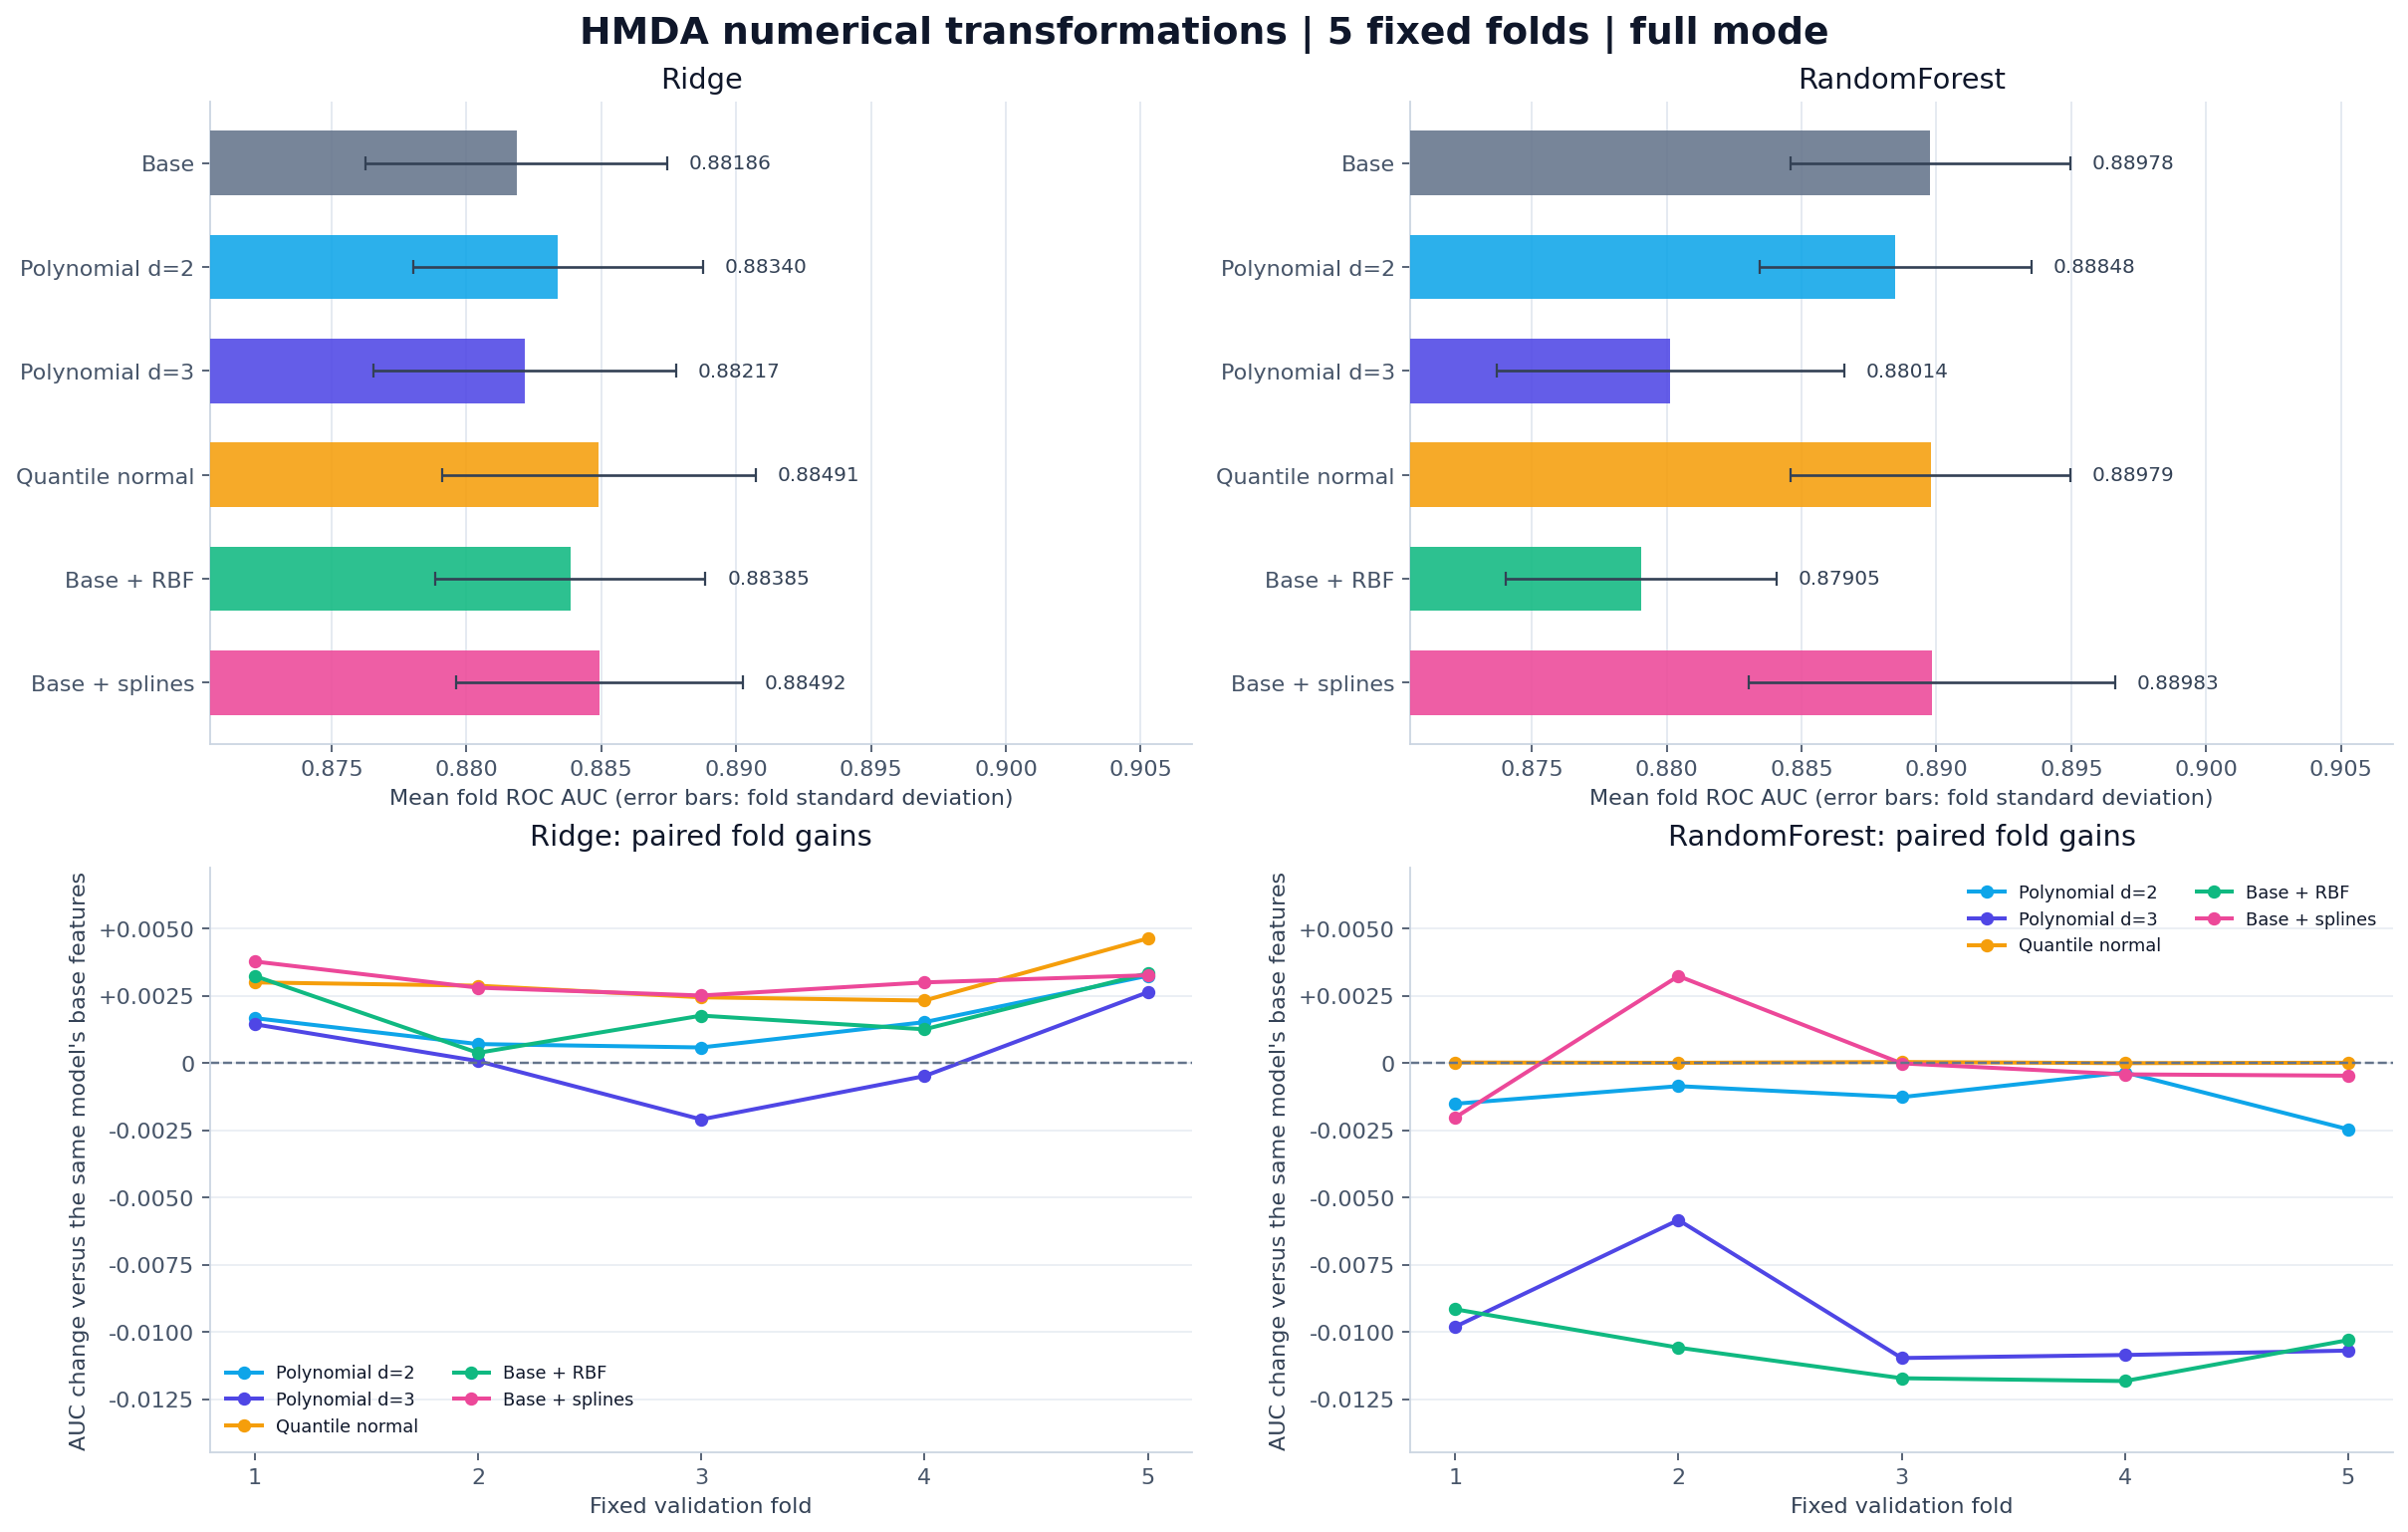

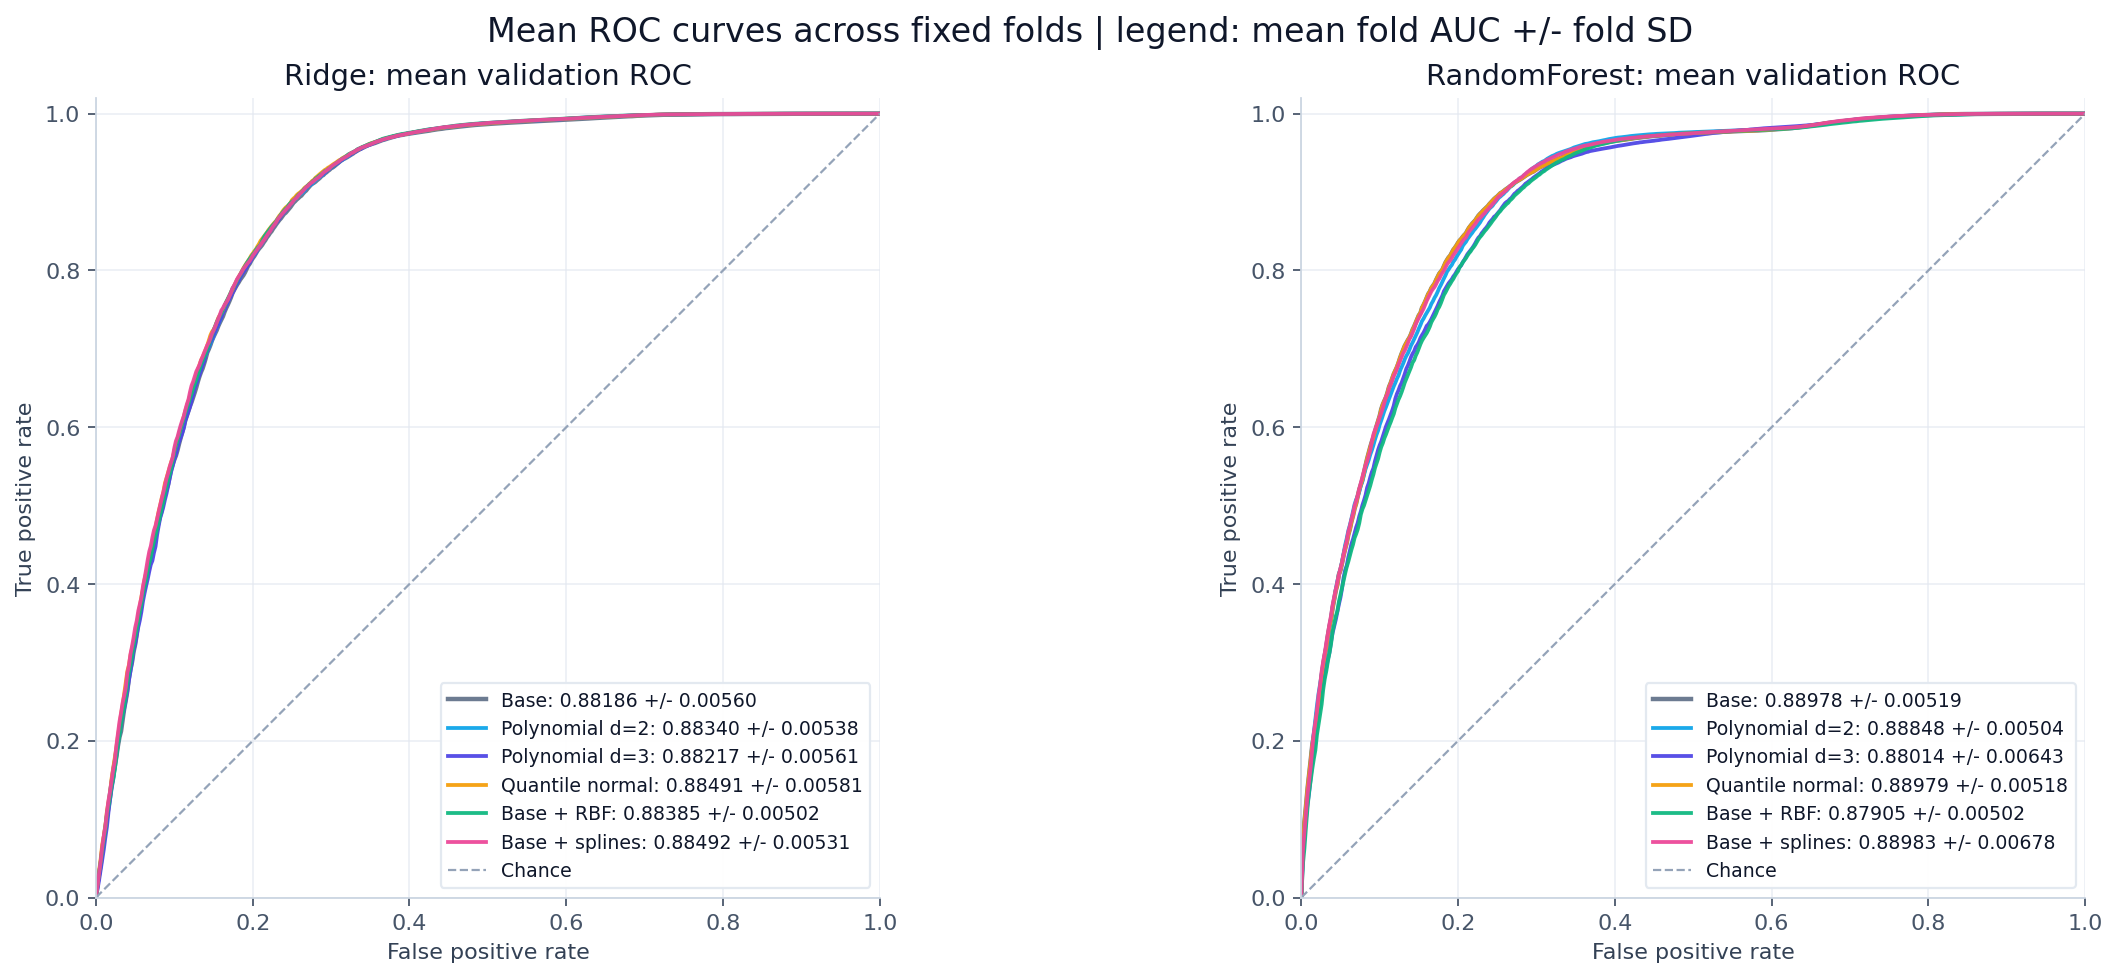

Verified results and figures saved to /Users/zyouwei/Documents/M2/app_supervise/projet/demandes-de-pret-immobilier-aux-etats-unis/artifacts/transformation_models/20261005T153713_490301Z_full


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import Image, display
from sklearn.metrics import roc_curve

_rep_colors = {"base": "#64748B", "poly2": "#0EA5E9", "poly3": "#4F46E5",
               "quantile": "#F59E0B", "rbf": "#10B981", "spline": "#EC4899"}
_rep_english = {"base": "Base", "poly2": "Polynomial d=2", "poly3": "Polynomial d=3",
                "quantile": "Quantile normal", "rbf": "Base + RBF", "spline": "Base + splines"}
_plot_style = {
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 13,
    "axes.labelsize": 10, "axes.edgecolor": "#CBD5E1", "axes.labelcolor": "#334155",
    "xtick.color": "#475569", "ytick.color": "#475569", "text.color": "#0F172A",
    "figure.facecolor": "white", "axes.facecolor": "white", "grid.color": "#E2E8F0",
    "axes.spines.top": False, "axes.spines.right": False,
}

try:
    with plt.rc_context(_plot_style):
        fig, axes = plt.subplots(2, len(MODEL_NAMES), figsize=(15, 9.5), squeeze=False,
                                 gridspec_kw={"height_ratios": [1.1, 1]}, constrained_layout=True)
        _lower = float((auc_summary["auc_mean"] - auc_summary["auc_std"]).min())
        _upper = float((auc_summary["auc_mean"] + auc_summary["auc_std"]).max())
        _span = max(_upper - _lower, 0.01)
        _auc_xlim = (max(0, _lower - 0.14 * _span), min(1, _upper + 0.45 * _span))
        _delta_low = min(0, float(paired_deltas["auc_delta"].min()))
        _delta_high = max(0, float(paired_deltas["auc_delta"].max()))
        _delta_span = max(_delta_high - _delta_low, 0.001)
        _delta_ylim = (_delta_low - 0.16 * _delta_span, _delta_high + 0.16 * _delta_span)

        for column, model in enumerate(MODEL_NAMES):
            table = auc_summary.loc[auc_summary["model"] == model].set_index("representation").loc[_reps]
            ax = axes[0, column]
            positions = np.arange(len(_reps))
            ax.barh(positions, table["auc_mean"], xerr=table["auc_std"],
                    color=[_rep_colors[r] for r in _reps], alpha=0.88, height=0.62,
                    error_kw={"ecolor": "#334155", "capsize": 3, "elinewidth": 1.2}, zorder=3)
            ax.set_yticks(positions, [_rep_english[r] for r in _reps])
            ax.invert_yaxis()
            ax.set_xlim(*_auc_xlim)
            ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.3f}"))
            ax.grid(axis="x", zorder=0)
            ax.set_xlabel("Mean fold ROC AUC (error bars: fold standard deviation)")
            ax.set_title(model)
            for y_position, row in enumerate(table.itertuples()):
                ax.text(row.auc_mean + row.auc_std + 0.035 * _span, y_position,
                        f"{row.auc_mean:.5f}", va="center", fontsize=9, color="#334155")

            ax = axes[1, column]
            for rep in _reps:
                if rep == "base":
                    continue
                rows = paired_deltas.loc[(paired_deltas["model"] == model) &
                                         (paired_deltas["representation"] == rep)].sort_values("fold")
                ax.plot(rows["fold"], rows["auc_delta"], marker="o", markersize=5, linewidth=1.8,
                        color=_rep_colors[rep], label=_rep_english[rep])
            ax.axhline(0, color="#64748B", linestyle="--", linewidth=1.1)
            ax.set_xticks(_fold_ids)
            ax.set_ylim(*_delta_ylim)
            ax.grid(axis="y", alpha=0.75)
            ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:+.4f}" if abs(value) > 1e-12 else "0"))
            ax.set_xlabel("Fixed validation fold")
            ax.set_ylabel("AUC change versus the same model's base features")
            ax.set_title(f"{model}: paired fold gains", pad=10)
            ax.legend(ncol=2, frameon=False, fontsize=8, loc="best")
        fig.suptitle(f"HMDA numerical transformations | {len(_fold_ids)} fixed folds | {RUN_MODE} mode",
                     fontsize=17, fontweight="bold")
        _auc_plot = RUN_DIR / "auc_comparison.png"
        fig.savefig(_auc_plot, dpi=160, bbox_inches="tight", facecolor="white")
        plt.close(fig)

        fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(15, 6), squeeze=False, constrained_layout=True)
        _fpr_grid = np.linspace(0, 1, 501)
        for column, model in enumerate(MODEL_NAMES):
            ax = axes[0, column]
            for rep in _reps:
                variant = f"{model}_{rep}"
                interpolated = []
                for fold in _fold_ids:
                    mask = _folds == fold
                    fpr, tpr, _ = roc_curve(_y[mask], _predictions.loc[mask, variant].to_numpy())
                    fold_tpr = np.interp(_fpr_grid, fpr, tpr)
                    fold_tpr[0], fold_tpr[-1] = 0, 1
                    interpolated.append(fold_tpr)
                mean_tpr = np.mean(interpolated, axis=0)
                row = auc_summary.loc[auc_summary["variant"] == variant].iloc[0]
                ax.plot(_fpr_grid, mean_tpr, color=_rep_colors[rep], linewidth=2 if rep == "base" else 1.7,
                        alpha=0.95, label=f"{_rep_english[rep]}: {row.auc_mean:.5f} +/- {row.auc_std:.5f}")
            ax.plot([0, 1], [0, 1], color="#94A3B8", linestyle="--", linewidth=1, label="Chance")
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.02)
            ax.set_aspect("equal", adjustable="box")
            ax.grid(alpha=0.65)
            ax.set_xlabel("False positive rate")
            ax.set_ylabel("True positive rate")
            ax.set_title(f"{model}: mean validation ROC")
            ax.legend(loc="lower right", fontsize=8.5, framealpha=0.95, edgecolor="#E2E8F0")
        fig.suptitle("Mean ROC curves across fixed folds | legend: mean fold AUC +/- fold SD", fontsize=15)
        _roc_plot = RUN_DIR / "mean_roc.png"
        fig.savefig(_roc_plot, dpi=160, bbox_inches="tight", facecolor="white")
        plt.close(fig)

    display(Image(filename=str(_auc_plot)))
    display(Image(filename=str(_roc_plot)))
    _report_status("complete", artifacts=["auc_summary.csv", "paired_auc_deltas.csv", "delta_summary.csv",
                                           "poly3_vs_poly2.csv", "auc_comparison.png", "mean_roc.png"])
    print(f"Verified results and figures saved to {RUN_DIR}")
except BaseException as exc:
    plt.close("all")
    _report_status("failed", error=f"{type(exc).__name__}: {exc}")
    raise

## 结果的适用范围

这轮预先固定所有参数，只比较不同数值表示；没有按外层 AUC 搜索 alpha、gamma、维度、结点数量或树参数。结果不能代表所有高阶或核变换的最优表现，也不能解释为显著性检验。

固定五折已用于本项目多轮探索，完整 OOF 是交叉验证结果，没有独立最终测试集的标签。进一步调参需要外层训练折内的验证或新的留出集。